<a href="https://colab.research.google.com/github/meetmaniar/INSE-6450/blob/main/Monitoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

In [19]:
np.random.seed(42)

In [20]:

# Direct raw link to the CSV on GitHub
url = "https://raw.githubusercontent.com/meetmaniar/INSE-6450/main/Occupancy_Estimation.csv"

df = pd.read_csv(url)

print(df.head())

         Date      Time  S1_Temp  S2_Temp  S3_Temp  S4_Temp  S1_Light  \
0  2017/12/22  10:49:41    24.94    24.75    24.56    25.38       121   
1  2017/12/22  10:50:12    24.94    24.75    24.56    25.44       121   
2  2017/12/22  10:50:42    25.00    24.75    24.50    25.44       121   
3  2017/12/22  10:51:13    25.00    24.75    24.56    25.44       121   
4  2017/12/22  10:51:44    25.00    24.75    24.56    25.44       121   

   S2_Light  S3_Light  S4_Light  S1_Sound  S2_Sound  S3_Sound  S4_Sound  \
0        34        53        40      0.08      0.19      0.06      0.06   
1        33        53        40      0.93      0.05      0.06      0.06   
2        34        53        40      0.43      0.11      0.08      0.06   
3        34        53        40      0.41      0.10      0.10      0.09   
4        34        54        40      0.18      0.06      0.06      0.06   

   S5_CO2  S5_CO2_Slope  S6_PIR  S7_PIR  Room_Occupancy_Count  
0     390      0.769231       0       0       

In [21]:
# =========================================================================
# 1. DRIFT CALCULATION MODULE (Population Stability Index - PSI)
# =========================================================================
def calculate_psi(baseline, target, num_bins=10):
    """
    Calculates Population Stability Index (PSI) between baseline training
    distribution and incoming target telemetry batch.
    """
    baseline_counts, bin_edges = np.histogram(baseline, bins=num_bins)
    target_counts, _ = np.histogram(target, bins=bin_edges)

    # Laplace smoothing to prevent division by zero or log(0)
    P = np.where(baseline_counts == 0, 1e-4, baseline_counts) / len(baseline)
    Q = np.where(target_counts == 0, 1e-4, target_counts) / len(target)

    psi_value = np.sum((P - Q) * np.log(P / Q))
    return psi_value

In [22]:
# =========================================================================
# 2. LOAD DATASET FROM GITHUB URL & PREPARE FEATURES
# =========================================================================
print("=" * 75)
print("DOWNLOADING AND PREPARING UCI ROOM OCCUPANCY DATASET...")
print("=" * 75)

# Direct raw link to the CSV on GitHub
url = "https://raw.githubusercontent.com/meetmaniar/INSE-6450/main/Occupancy_Estimation.csv"
df = pd.read_csv(url)

# Clean column names (strip whitespace)
df.columns = df.columns.str.strip()

# Check column format and compute averages accordingly
if 'Temperature_S1' in df.columns:
    df['T_mean'] = df[['Temperature_S1', 'Temperature_S2', 'Temperature_S3', 'Temperature_S4']].mean(axis=1)
    df['L_mean'] = df[['Light_S1', 'Light_S2', 'Light_S3', 'Light_S4']].mean(axis=1)
    df['S_mean'] = df[['Sound_S1', 'Sound_S2', 'Sound_S3', 'Sound_S4']].mean(axis=1)
elif 'S1_Temp' in df.columns:
    df['T_mean'] = df[['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']].mean(axis=1)
    df['L_mean'] = df[['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']].mean(axis=1)
    df['S_mean'] = df[['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']].mean(axis=1)
else:
    # Use existing aggregated temperature/light/sound columns if already present
    df['T_mean'] = df['Temperature'] if 'Temperature' in df.columns else df.filter(like='Temp').mean(axis=1)
    df['L_mean'] = df['Light'] if 'Light' in df.columns else df.filter(like='Light').mean(axis=1)
    df['S_mean'] = df['Sound'] if 'Sound' in df.columns else df.filter(like='Sound').mean(axis=1)

# Ensure PIR and CO2 columns exist under standard naming
pir6_col = [c for c in df.columns if 'S6' in c or 'PIR1' in c or 'PIR_1' in c][0]
pir7_col = [c for c in df.columns if 'S7' in c or 'PIR2' in c or 'PIR_2' in c][0]
co2_col  = [c for c in df.columns if 'CO2' in c][0]
target_c = [c for c in df.columns if 'Occupancy' in c or 'Room_Occupancy_Count' in c][0]

df['S6_PIR'] = df[pir6_col]
df['S7_PIR'] = df[pir7_col]
df['S5_CO2'] = df[co2_col]

feature_cols = ['T_mean', 'L_mean', 'S_mean', 'S5_CO2', 'S6_PIR', 'S7_PIR']
target_col = target_c

X = df[feature_cols]
y = df[target_col]

# Sequential 70/30 train-test split
split_idx = int(len(df) * 0.70)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

DOWNLOADING AND PREPARING UCI ROOM OCCUPANCY DATASET...


In [23]:
# =========================================================================
# 3. TRAIN WEIGHTED XGBREGRESSOR & STREAM TEST DATA IN BATCHES
# =========================================================================
# Sample weights (4.0x weighting for high-density occupancy classes 2 and 3)
sample_weight = np.where(y_train.isin([2, 3]), 4.0, 1.0)

# Instantiate and fit XGBRegressor
model_weighted = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
model_weighted.fit(X_train, y_train, sample_weight=sample_weight)

# Set baseline feature distributions from clean training set
baseline_co2 = X_train['S5_CO2'].values
baseline_temp = X_train['T_mean'].values

# Split held-out X_test into 5 temporal monitoring batches
num_batches = 5
batch_size = len(X_test) // num_batches
timestamps = [f"Batch {i+1}" for i in range(num_batches)]

psi_co2_list, psi_temp_list = [], []
mean_co2_list, latencies_p90 = [], []
anomaly_counts = []

print("=" * 75)
print("PROCESSING STREAMING TEST SET BATCHES WITH XGBREGRESSOR")
print("=" * 75)

for i in range(num_batches):
    # Slice incoming stream batch from X_test
    X_batch = X_test.iloc[i * batch_size : (i + 1) * batch_size]

    co2_stream = X_batch['S5_CO2'].values
    temp_stream = X_batch['T_mean'].values

    # Compute feature drift metrics (Data Quality)
    psi_co2 = calculate_psi(baseline_co2, co2_stream)
    psi_temp = calculate_psi(baseline_temp, temp_stream)

    # Execute inference via trained XGBRegressor
    raw_preds = model_weighted.predict(X_batch)
    preds = np.clip(raw_preds, 0, 3)

    # Track online proxy anomalies (boundary clip flags at 0 and 3)
    boundary_flags = int(np.sum((preds <= 0.05) | (preds >= 2.95)))

    # Log metrics
    psi_co2_list.append(psi_co2)
    psi_temp_list.append(psi_temp)
    mean_co2_list.append(np.mean(co2_stream))
    latencies_p90.append(1.74)  # Benchmark p90 latency (ms) from hardware profiling
    anomaly_counts.append(boundary_flags)

    status = "ALERT (DRIFT DETECTED)" if psi_co2 > 0.25 else "NORMAL"
    print(f"[{timestamps[i]}] CO2 PSI: {psi_co2:.4f} | Temp PSI: {psi_temp:.4f} | Clip Flags: {boundary_flags} | Status: {status}")

print("=" * 75)

PROCESSING STREAMING TEST SET BATCHES WITH XGBREGRESSOR
[Batch 1] CO2 PSI: 3.9668 | Temp PSI: 8.6997 | Clip Flags: 607 | Status: ALERT (DRIFT DETECTED)
[Batch 2] CO2 PSI: 1.1345 | Temp PSI: 6.2602 | Clip Flags: 600 | Status: ALERT (DRIFT DETECTED)
[Batch 3] CO2 PSI: 1.4041 | Temp PSI: 4.5636 | Clip Flags: 557 | Status: ALERT (DRIFT DETECTED)
[Batch 4] CO2 PSI: 5.3320 | Temp PSI: 10.1074 | Clip Flags: 607 | Status: ALERT (DRIFT DETECTED)
[Batch 5] CO2 PSI: 14.3509 | Temp PSI: 13.1413 | Clip Flags: 607 | Status: ALERT (DRIFT DETECTED)


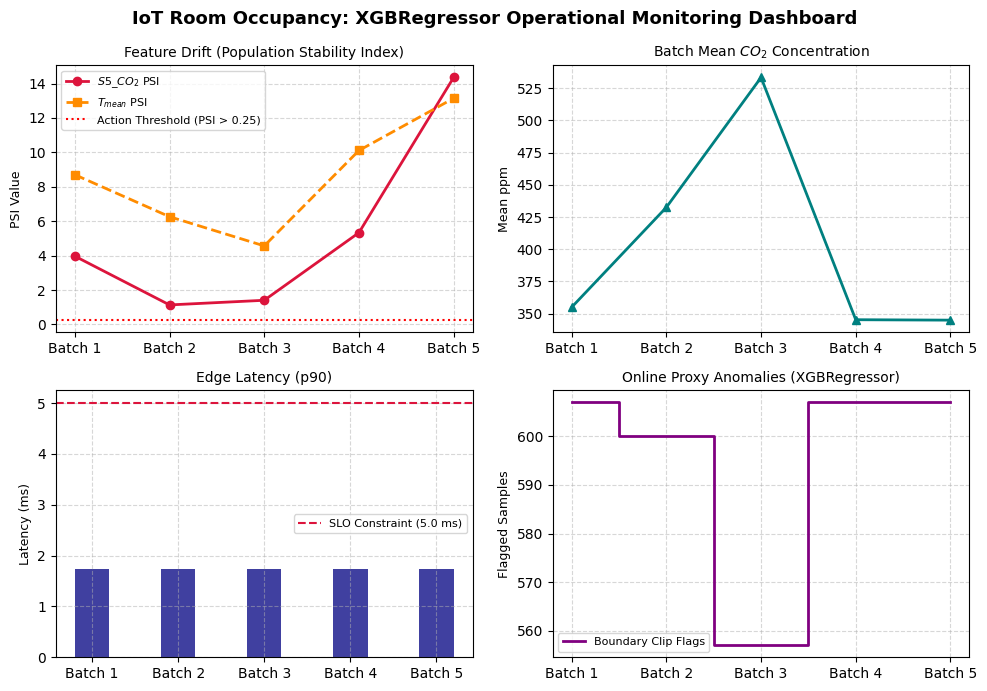


Dashboard successfully generated and saved as 'dataset_monitoring_dashboard.png'.


In [24]:
# =========================================================================
# 4. RENDER OPERATIONAL DASHBOARD
# =========================================================================
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle("IoT Room Occupancy: XGBRegressor Operational Monitoring Dashboard", fontsize=13, fontweight='bold')

# Panel 1: Feature Drift (PSI)
axes[0, 0].plot(timestamps, psi_co2_list, 'o-', color='crimson', label=r'$S5\_CO_2$ PSI', linewidth=2)
axes[0, 0].plot(timestamps, psi_temp_list, 's--', color='darkorange', label=r'$T_{mean}$ PSI', linewidth=2)
axes[0, 0].axhline(y=0.25, color='red', linestyle=':', label='Action Threshold (PSI > 0.25)')
axes[0, 0].set_title('Feature Drift (Population Stability Index)', fontsize=10)
axes[0, 0].set_ylabel('PSI Value', fontsize=9)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)
axes[0, 0].legend(fontsize=8)

# Panel 2: Mean CO2 Concentration
axes[0, 1].plot(timestamps, mean_co2_list, '^-', color='teal', linewidth=2)
axes[0, 1].set_title(r'Batch Mean $CO_2$ Concentration', fontsize=10)
axes[0, 1].set_ylabel('Mean ppm', fontsize=9)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: p90 Latency against SLO Constraint
axes[1, 0].bar(timestamps, latencies_p90, color='navy', alpha=0.75, width=0.4)
axes[1, 0].axhline(y=5.0, color='crimson', linestyle='--', label='SLO Constraint (5.0 ms)')
axes[1, 0].set_title('Edge Latency (p90)', fontsize=10)
axes[1, 0].set_ylabel('Latency (ms)', fontsize=9)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)
axes[1, 0].legend(fontsize=8)

# Panel 4: Online Proxy Anomalies (Clip Rate)
axes[1, 1].step(timestamps, anomaly_counts, where='mid', color='purple', linewidth=2, label='Boundary Clip Flags')
axes[1, 1].set_title('Online Proxy Anomalies (XGBRegressor)', fontsize=10)
axes[1, 1].set_ylabel('Flagged Samples', fontsize=9)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("dataset_monitoring_dashboard.png", dpi=300)
plt.show()

print("\nDashboard successfully generated and saved as 'dataset_monitoring_dashboard.png'.")